# 02 — Civilian NHANES men, calibrated to the active-duty Army

**Goal.** Reproduce every number in Hennigar et al. (JAMA 2026) that can
be reproduced from public data: the prevalence of a single morning total
testosterone below 300 and 264 ng/dL, overall and by age / obesity
subgroup; mean total T, SHBG and free T; survey-weighted odds ratios per
5 years of age and 5 BMI units; and the testosterone-by-age scatterplot.

**Design mimicry.** MHANES used poststratification calibration weights
to the active-duty Army on sex, race/ethnicity and rank. Here NHANES
2021–2023 morning-session men aged 18–59 are **raked** from their
phlebotomy weights to the September 2021 active-duty Army distribution
of age group and race/ethnicity (DoD *2021 Demographics Profile*,
tables 2.14, 2.24, 2.27–2.28, 2.44). Rank has no civilian analogue; age
stands in for it. Variances use NHANES strata/PSU with Taylor
linearisation, as the paper did with its strata and PSUs.

**What cannot be matched** (discussed at the end): assay (NHANES
LC-MS/MS vs. MHANES Siemens IMMULITE 2000 immunoassay), the
testosterone-therapy exclusion (drug names are not released for
2021–2023), and the soldier population itself.


In [1]:
import os, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.nonparametric.smoothers_lowess import lowess
from survey_utils import svy_mean, rake, svy_logit

DATA_DIR = Path(os.path.abspath(os.path.join('..', 'data')))
men = pd.read_parquet(DATA_DIR / 'derived' / 'nhanes_testosterone_men_18_59.parquet')

# Published MHANES values (Hennigar et al. 2026, Table and text)
PAPER = {
    'n': 479, 'mean_age': 29.9, 'mean_bmi': 28.4,
    'mean_tt': (405, 368, 442), 'mean_shbg_ugml': (3.24, 2.73, 3.75), 'mean_ft': (8.74, 7.70, 9.81),
    'prev': {  # (subgroup, threshold): (n_low, pct, lo, hi)
        ('Overall', 300): (124, 25.7, 16.8, 34.5), ('Overall', 264): (70, 14.7, 9.7, 19.7),
        ('<30 y', 300): (53, 19.5, 11.1, 28.0),   ('<30 y', 264): (30, 11.4, 4.6, 18.1),
        ('>=30 y', 300): (71, 32.8, 24.6, 40.9),  ('>=30 y', 264): (40, 18.6, 15.3, 21.9),
        ('Nonobese 19-39 y', 264): (28, 9.7, 4.6, 14.8),
    },
    'high_916': (7, 1.3, 0.0, 3.2),
    'or': {('age/5', 300): (1.29, 1.17, 1.43), ('age/5', 264): (1.20, 1.14, 1.27),
           ('bmi/5', 300): (1.90, 1.28, 2.83), ('bmi/5', 264): (1.82, 1.07, 3.10)},
    'army_counts': {300: 100691, 264: 57788},
}


## Analytic sample

MHANES: fasting morning draw, men, 3 men on testosterone therapy
excluded → n = 479. NHANES 2021–2023: men 18–59 examined in the morning
(fasting) session with a testosterone result. The 2021–2023 prescription
file carries no drug names, so no therapy exclusion is possible here;
the pooled 2011–2016 sensitivity analysis below applies it.


In [2]:
d = men[(men['cycle'] == '2021-2023') & men['morning']].copy().reset_index(drop=True)
print(f'NHANES 2021-2023 morning-session men 18-59 with total T: n = {len(d)}')
print(f'  missing BMI: {d.bmi.isna().sum()}, missing albumin: {d.albumin.isna().sum()}')
print(f'  fasting hours: median {d.fast_hr.median():.0f}, IQR {d.fast_hr.quantile(.25):.0f}-{d.fast_hr.quantile(.75):.0f}')
print(f'  design: {d.strata.nunique()} strata, {d.groupby("strata").psu.nunique().sum()} PSUs')


NHANES 2021-2023 morning-session men 18-59 with total T: n = 784
  missing BMI: 4, missing albumin: 24
  fasting hours: median 12, IQR 10-14
  design: 15 strata, 30 PSUs


## Calibration to the active-duty Army

Population margins come from the DoD *2021 Demographics Profile of the
Military Community* (DMDC Active Duty Master File, September 2021),
Army column, enlisted + officers combined:

* **Age** (table 2.44): ≤25 y 208,004; 26–30 y 106,630; 31–35 y 70,684;
  36–40 y 52,710; ≥41 y 44,387 (total 482,416, both sexes).
* **Race/ethnicity** (tables 2.24, 2.27, 2.28): Army Hispanic 82,245
  (17.0%); the non-Hispanic race counts apply the DoD-wide
  Hispanic share within each race (table 2.27) to the Army race totals
  (table 2.24): NH White 262,794; NH Black 96,148; NH Asian 24,153;
  NH other (AIAN, NHOPI, unknown) 17,076.
* **Men** (table 2.14): 407,543 active-duty Army men. The paper's
  Army-wide counts imply a slightly smaller denominator
  (100,691 / 0.257 ≈ 392,000).

Age margins are reported for both sexes; the male age distribution is
assumed to match. The NHANES 41–59 group is matched to the Army ≥41
group (Army members older than 59 are negligible).


In [3]:
ARMY_MEN = 407_543
ARMY_AGE = {'18-25': 208_004, '26-30': 106_630, '31-35': 70_684, '36-40': 52_710, '41-59': 44_387}
ARMY_RACE = {'Hispanic': 82_245, 'NH White': 262_794, 'NH Black': 96_148, 'NH Asian': 24_153, 'NH Other': 17_076}

d['w_us'] = d['wt']                                             # civilian US (phlebotomy weight)
d['w_army'] = rake(d['wt'], d, {'age_grp': ARMY_AGE, 'race5': ARMY_RACE}) * ARMY_MEN / sum(ARMY_AGE.values())

comp = pd.DataFrame({
    'n (unweighted)': pd.concat([d.age_grp.value_counts(), d.race5.value_counts()]),
    'US civilian %': pd.concat([d.groupby('age_grp').w_us.sum(), d.groupby('race5').w_us.sum()]) / d.w_us.sum() * 100,
    'Army target %': pd.Series({**ARMY_AGE, **ARMY_RACE}) / sum(ARMY_AGE.values()) * 100,
    'Calibrated %': pd.concat([d.groupby('age_grp').w_army.sum(), d.groupby('race5').w_army.sum()]) / d.w_army.sum() * 100,
}).round(1)
print(f'weight ratio (calibrated / base): min {np.min(d.w_army/d.w_us*d.w_us.sum()/d.w_army.sum()):.2f}, '
      f'max {np.max(d.w_army/d.w_us*d.w_us.sum()/d.w_army.sum()):.2f}')
comp


weight ratio (calibrated / base): min 0.10, max 3.96


,n (unweighted),US civilian %,Army target %,Calibrated %
18-25,142,20.1,43.1,43.1
26-30,78,12.0,22.1,22.1
31-35,105,12.6,14.7,14.7
36-40,85,11.2,10.9,10.9
41-59,374,44.1,9.2,9.2
Hispanic,190,21.5,17.0,17.0
NH Asian,44,5.8,5.0,5.0
NH Black,93,10.3,19.9,19.9
NH Other,51,5.7,3.5,3.5
NH White,406,56.6,54.5,54.5


## Table: prevalence of low, normal and high total testosterone

Same layout as the paper's Table. "Low" is below the cutoff, "normal" is
cutoff through 916 ng/dL and "high" is above 916 ng/dL (the harmonised
upper reference limit of Travison et al. 2017). NHANES columns use the
Army-calibrated weights; the paper's values sit alongside.


In [4]:
def prev_row(df, w, mask, thr):
    low = svy_mean(df.total_t < thr, df[w], df.strata, df.psu, domain=mask)
    normal = svy_mean((df.total_t >= thr) & (df.total_t <= 916), df[w], df.strata, df.psu, domain=mask)
    high = svy_mean(df.total_t > 916, df[w], df.strata, df.psu, domain=mask)
    n_low = int(((df.total_t < thr) & mask).sum()); n_norm = int((((df.total_t >= thr) & (df.total_t <= 916)) & mask).sum())
    n_high = int(((df.total_t > 916) & mask).sum())
    fmt = lambda r: f"{100*r['est']:.1f} ({100*max(r['lo'],0):.1f}-{100*r['hi']:.1f})"
    return {'n': int(mask.sum()), 'low n': n_low, 'low % (95% CI)': fmt(low),
            'normal n': n_norm, 'normal % (95% CI)': fmt(normal), 'high n': n_high, 'high % (95% CI)': fmt(high),
            '_low': low}

SUBGROUPS = {
    'Overall': np.ones(len(d), bool),
    '<30 y': (d.age < 30).values,
    '>=30 y': (d.age >= 30).values,
    'Nonobese 19-39 y': ((d.bmi < 30) & d.age.between(19, 39)).values,
}
rows, results = [], {}
for sub, mask in SUBGROUPS.items():
    for thr in ([264] if sub.startswith('Nonobese') else [300, 264]):
        r = prev_row(d, 'w_army', mask, thr)
        results[(sub, thr)] = r.pop('_low')
        p = PAPER['prev'][(sub, thr)]
        rows.append({'subgroup': sub, 'cutoff': f'<{thr}', **r,
                     'MHANES low n': p[0], 'MHANES low % (95% CI)': f'{p[1]:.1f} ({p[2]:.1f}-{p[3]:.1f})'})
table = pd.DataFrame(rows).set_index(['subgroup', 'cutoff'])
table


n  low n   low % (95% CI)  normal n  \
subgroup         cutoff                                          
Overall          <300    784    122  12.7 (7.4-18.0)       625   
                 <264    784     73   6.5 (2.8-10.3)       674   
<30 y            <300    199     17  10.7 (5.2-16.2)       169   
                 <264    199      7    4.6 (0.1-9.0)       179   
>=30 y           <300    585    105  15.6 (8.3-23.0)       456   
                 <264    585     66   9.3 (4.6-14.1)       495   
Nonobese 19-39 y <264    234      3    0.6 (0.0-1.3)       215   

                        normal % (95% CI)  high n high % (95% CI)  \
subgroup         cutoff                                             
Overall          <300    80.7 (75.1-86.4)      37  6.6 (2.4-10.8)   
                 <264    86.9 (82.3-91.5)      37  6.6 (2.4-10.8)   
<30 y            <300    83.3 (76.3-90.3)      13  6.0 (1.7-10.4)   
                 <264    89.4 (83.8-94.9)      13  6.0 (1.7-10.4)   
>=30 y           <300    77.0 (70.0-84.0)      24  7.3 (2.5-12.2)   
                 <264    83.3 (77.3-89.4)      24  7.3 (2.5-12.2)   
Nonobese 19-39 y <264    90.8 (83.6-98.0)      16  8.6 (1.3-15.9)   

                         MHANES low n MHANES low % (95% CI)  
subgroup         cutoff                                      
Overall          <300             124      25.7 (16.8-34.5)  
                 <264              70       14.7 (9.7-19.7)  
<30 y            <300              53      19.5 (11.1-28.0)  
                 <264              30       11.4 (4.6-18.1)  
>=30 y           <300              71      32.8 (24.6-40.9)  
                 <264              40      18.6 (15.3-21.9)  
Nonobese 19-39 y <264              28        9.7 (4.6-14.8)

## Means: age, BMI, total T, SHBG, free T

SHBG is reported by NHANES in nmol/L; the paper reports µg/mL. The
conversion uses a molecular mass of 95 kDa (1 nmol/L ≈ 0.095 µg/mL),
which is approximate because SHBG is a glycoprotein of variable mass.


In [5]:
def ci_str(r, nd=1):
    return f"{r['est']:.{nd}f} ({r['lo']:.{nd}f}-{r['hi']:.{nd}f})"

means = {
    'mean age, y': (ci_str(svy_mean(d.age, d.w_army, d.strata, d.psu)), f"{PAPER['mean_age']} (SE 0.6)"),
    'mean BMI': (ci_str(svy_mean(d.bmi, d.w_army, d.strata, d.psu, domain=d.bmi.notna())), f"{PAPER['mean_bmi']} (SE 0.2)"),
    'total testosterone, ng/dL': (ci_str(svy_mean(d.total_t, d.w_army, d.strata, d.psu), 0), '405 (368-442)'),
    'SHBG, nmol/L': (ci_str(svy_mean(d.shbg, d.w_army, d.strata, d.psu)), '—'),
    'SHBG, µg/mL (×0.095)': (ci_str(svy_mean(d.shbg * 0.095, d.w_army, d.strata, d.psu), 2), '3.24 (2.73-3.75)'),
    'free testosterone, ng/dL': (ci_str(svy_mean(d.free_t, d.w_army, d.strata, d.psu, domain=d.free_t.notna()), 2), '8.74 (7.70-9.81)'),
    'median total testosterone, ng/dL': (f"{d.total_t.median():.0f} (unweighted)", '—'),
}
pd.DataFrame(means, index=['NHANES 2021-23 men, Army-calibrated', 'MHANES (paper)']).T


,"NHANES 2021-23 men, Army-calibrated",MHANES (paper)
"mean age, y",29.2 (28.2-30.1),29.9 (SE 0.6)
mean BMI,28.1 (26.9-29.3),28.4 (SE 0.2)
"total testosterone, ng/dL",549 (500-597),405 (368-442)
"SHBG, nmol/L",30.6 (28.7-32.5),—
"SHBG, µg/mL (×0.095)",2.91 (2.73-3.09),3.24 (2.73-3.75)
"free testosterone, ng/dL",12.55 (10.88-14.23),8.74 (7.70-9.81)
"median total testosterone, ng/dL",476 (unweighted),—


## Survey-weighted logistic regression: age and BMI

The paper reports one odds ratio per 5-year age increase and one per
5-unit BMI increase for each threshold; it does not say whether age and
BMI were in the same model. Both specifications are shown.


In [6]:
dm = d[d.bmi.notna()].reset_index(drop=True)
X_both = np.column_stack([np.ones(len(dm)), dm.age / 5, dm.bmi / 5])
or_rows = []
for thr in [300, 264]:
    y = (dm.total_t < thr).values
    joint = svy_logit(X_both, y, dm.w_army, dm.strata, dm.psu, names=['intercept', 'age/5', 'bmi/5'])
    age_only = svy_logit(X_both[:, :2], y, dm.w_army, dm.strata, dm.psu, names=['intercept', 'age/5'])
    bmi_only = svy_logit(X_both[:, [0, 2]], y, dm.w_army, dm.strata, dm.psu, names=['intercept', 'bmi/5'])
    for term, single in [('age/5', age_only), ('bmi/5', bmi_only)]:
        p = PAPER['or'][(term, thr)]
        or_rows.append({'cutoff': f'<{thr}', 'term': term,
                        'NHANES OR, single predictor': f"{single.loc[term,'OR']:.2f} ({single.loc[term,'OR_lo']:.2f}-{single.loc[term,'OR_hi']:.2f})",
                        'NHANES OR, age + BMI jointly': f"{joint.loc[term,'OR']:.2f} ({joint.loc[term,'OR_lo']:.2f}-{joint.loc[term,'OR_hi']:.2f})",
                        'MHANES OR (paper)': f'{p[0]:.2f} ({p[1]:.2f}-{p[2]:.2f})'})
or_table = pd.DataFrame(or_rows).set_index(['cutoff', 'term'])
or_table


NHANES OR, single predictor NHANES OR, age + BMI jointly  \
cutoff term                                                             
<300   age/5            1.19 (1.07-1.34)             1.15 (0.99-1.35)   
       bmi/5            1.71 (1.25-2.35)             1.70 (1.26-2.29)   
<264   age/5            1.20 (1.03-1.41)             1.16 (0.95-1.42)   
       bmi/5            1.88 (1.32-2.68)             1.88 (1.35-2.62)   

             MHANES OR (paper)  
cutoff term                     
<300   age/5  1.29 (1.17-1.43)  
       bmi/5  1.90 (1.28-2.83)  
<264   age/5  1.20 (1.14-1.27)  
       bmi/5  1.82 (1.07-3.10)

## Figure: total testosterone across age

Replicates the paper's Figure for the NHANES men: each point is one
participant, horizontal lines mark 300 and 264 ng/dL, the vertical line
marks age 30, and the orange curve is an unweighted LOWESS smooth, as
in the paper.


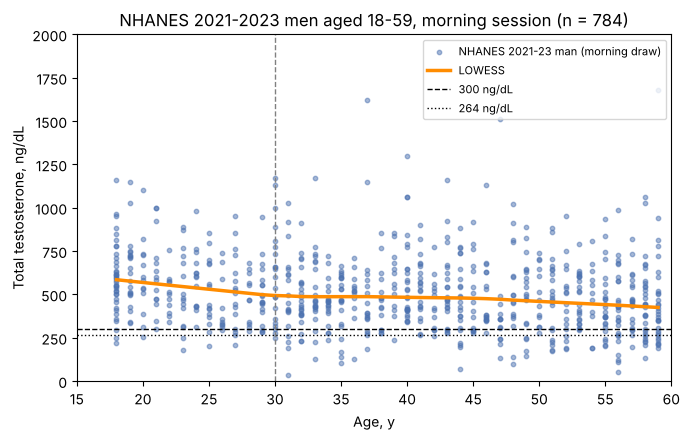

In [7]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(d.age, d.total_t, s=10, alpha=0.5, color='#4c72b0', label='NHANES 2021-23 man (morning draw)')
sm = lowess(d.total_t, d.age, frac=0.5)
ax.plot(sm[:, 0], sm[:, 1], color='darkorange', lw=2.5, label='LOWESS')
ax.axhline(300, ls='--', color='k', lw=1, label='300 ng/dL')
ax.axhline(264, ls=':', color='k', lw=1, label='264 ng/dL')
ax.axvline(30, ls='--', color='grey', lw=1)
ax.set_xlim(15, 60); ax.set_ylim(0, 2000)
ax.set_xlabel('Age, y'); ax.set_ylabel('Total testosterone, ng/dL')
ax.set_title(f'NHANES 2021-2023 men aged 18-59, morning session (n = {len(d)})')
ax.legend(loc='upper right', fontsize=8)
plt.tight_layout(); plt.show()


## Figure: MHANES vs calibrated NHANES, with 95% CIs

Three estimates per subgroup/cutoff: the paper's active-duty Army value,
NHANES men calibrated to Army age and race/ethnicity, and NHANES men
with their ordinary civilian weights (all US men 18–59).


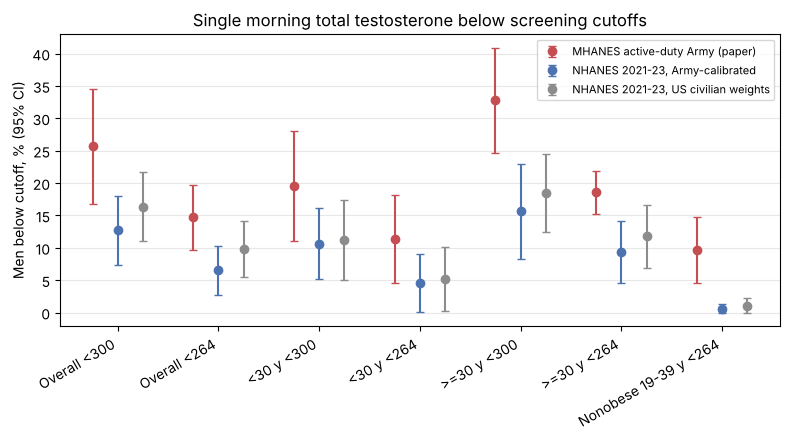

In [8]:
labels = [f'{s} {"<"+str(t)}' for (s, t) in results]
fig, ax = plt.subplots(figsize=(8, 4.5))
xs = np.arange(len(labels))
for off, (name, color) in zip([-0.25, 0, 0.25], [('MHANES active-duty Army (paper)', '#c44e52'),
                                                 ('NHANES 2021-23, Army-calibrated', '#4c72b0'),
                                                 ('NHANES 2021-23, US civilian weights', '#8c8c8c')]):
    est, lo, hi = [], [], []
    for (s, t) in results:
        if name.startswith('MHANES'):
            p = PAPER['prev'][(s, t)]; e, l, h = p[1], p[2], p[3]
        else:
            w = 'w_army' if 'calibrated' in name else 'w_us'
            r = svy_mean(d.total_t < t, d[w], d.strata, d.psu, domain=SUBGROUPS[s])
            e, l, h = 100 * r['est'], 100 * max(r['lo'], 0), 100 * r['hi']
        est.append(e); lo.append(e - l); hi.append(h - e)
    ax.errorbar(xs + off, est, yerr=[lo, hi], fmt='o', capsize=3, color=color, label=name)
ax.set_xticks(xs); ax.set_xticklabels(labels, rotation=30, ha='right')
ax.set_ylabel('Men below cutoff, % (95% CI)')
ax.set_title('Single morning total testosterone below screening cutoffs')
ax.legend(fontsize=8); ax.grid(axis='y', alpha=0.3)
plt.tight_layout(); plt.show()


## Implied Army-wide counts

The paper multiplies prevalence by the active-duty Army male population
(≈392,000 implied). The same arithmetic with the NHANES-calibrated
prevalence and the 2021 DMDC count of 407,543 Army men:


In [9]:
counts = pd.DataFrame({
    'NHANES-calibrated prevalence %': [100 * results[('Overall', t)]['est'] for t in [300, 264]],
    'implied Army men (407,543 base)': [results[('Overall', t)]['est'] * ARMY_MEN for t in [300, 264]],
    'MHANES prevalence % (paper)': [PAPER['prev'][('Overall', t)][1] for t in [300, 264]],
    'MHANES Army men (paper)': [PAPER['army_counts'][t] for t in [300, 264]],
}, index=['<300 ng/dL', '<264 ng/dL'])
counts.round({'NHANES-calibrated prevalence %': 1, 'implied Army men (407,543 base)': 0}).astype({'implied Army men (407,543 base)': int})


,NHANES-calibrated prevalence %,"implied Army men (407,543 base)",MHANES prevalence % (paper),MHANES Army men (paper)
<300 ng/dL,12.7,51747,25.7,100691
<264 ng/dL,6.5,26580,14.7,57788


## Sensitivity analyses

1. **Session timing.** Testosterone falls through the day. Including
   afternoon/evening NHANES men (what analyses that ignore draw time, e.g.
   Lokeshwar et al. 2021, do) raises the prevalence of a low value.
2. **Pooled 2011–2016 cycles.** Three earlier cycles, same LC-MS/MS
   method, with men on testosterone prescriptions excluded (as in the
   paper). Weights are `WTMEC2YR / 3`, raked to the same Army margins.
3. **Uncalibrated civilian estimate** for reference.
4. **Assay shift.** NHANES testosterone is LC-MS/MS; MHANES used the
   Siemens IMMULITE 2000 immunoassay. The second cell below asks what
   the NHANES prevalence would be if every value were scaled down by a
   constant factor: 10%, 15%, 20%, and the factor that equates the two
   studies' mean total testosterone (405 / 549 ≈ 0.74).


In [10]:
def headline(df, w, label):
    out = {'sample': label, 'n': len(df)}
    for thr in [300, 264]:
        r = svy_mean(df.total_t < thr, df[w], df.strata, df.psu)
        out[f'<{thr} % (95% CI)'] = f"{100*r['est']:.1f} ({100*max(r['lo'],0):.1f}-{100*r['hi']:.1f})"
    r = svy_mean(df.total_t, df[w], df.strata, df.psu)
    out['mean TT ng/dL (95% CI)'] = f"{r['est']:.0f} ({r['lo']:.0f}-{r['hi']:.0f})"
    return out

sens = [headline(d, 'w_army', '2021-23 morning, Army-calibrated (primary)'),
        headline(d, 'w_us', '2021-23 morning, US civilian weights')]

# all sessions, 2021-23
a = men[men['cycle'] == '2021-2023'].copy().reset_index(drop=True)
a['w_army'] = rake(a['wt'], a, {'age_grp': ARMY_AGE, 'race5': ARMY_RACE})
sens.append(headline(a, 'w_army', '2021-23 all sessions (morning + afternoon/evening), Army-calibrated'))
pm = a[~a.morning].copy().reset_index(drop=True)
pm['w_army'] = rake(pm['wt'], pm, {'age_grp': ARMY_AGE, 'race5': ARMY_RACE})
sens.append(headline(pm, 'w_army', '2021-23 afternoon/evening only, Army-calibrated'))

# pooled 2011-2016, morning, TRT excluded
p = men[men['cycle'].isin(['2011-2012', '2013-2014', '2015-2016']) & men['morning']].copy()
n_trt = int((p.trt == 1).sum())
p = p[p.trt != 1].reset_index(drop=True)
p['wt'] = p['wt'] / 3
# strata/PSU codes are cycle-specific; make them unique across cycles
p['strata'] = (p['cycle'].str[:4].astype(int) * 1000 + p['strata'])
p['w_army'] = rake(p['wt'], p, {'age_grp': ARMY_AGE, 'race5': ARMY_RACE})
sens.append(headline(p, 'w_army', f'2011-16 pooled morning, {n_trt} testosterone-Rx users excluded, Army-calibrated'))
sens.append(headline(p, 'wt', '2011-16 pooled morning, US civilian weights'))
sens_table = pd.DataFrame(sens).set_index('sample')
sens_table


,n,<300 % (95% CI),<264 % (95% CI),mean TT ng/dL (95% CI)
sample,,,,
"2021-23 morning, Army-calibrated (primary)",784,12.7 (7.4-18.0),6.5 (2.8-10.3),549 (500-597)
"2021-23 morning, US civilian weights",784,16.4 (11.0-21.7),9.8 (5.6-14.1),512 (479-546)
"2021-23 all sessions (morning + afternoon/evening), Army-calibrated",1443,17.5 (13.4-21.5),11.0 (7.6-14.3),505 (466-545)
"2021-23 afternoon/evening only, Army-calibrated",659,22.8 (17.4-28.2),15.7 (11.2-20.2),457 (420-494)
"2011-16 pooled morning, 8 testosterone-Rx users excluded, Army-calibrated",2557,14.2 (11.3-17.0),9.0 (6.8-11.1),487 (472-503)
"2011-16 pooled morning, US civilian weights",2557,17.8 (15.2-20.4),11.4 (9.4-13.5),458 (447-469)


In [11]:
mean_ratio = PAPER['mean_tt'][0] / svy_mean(d.total_t, d.w_army, d.strata, d.psu)['est']
shift_rows = []
for f in [1.0, 0.9, 0.85, 0.8, mean_ratio]:
    row = {'scale factor': f'{f:.2f}' + (' (equal means)' if f == mean_ratio else '')}
    for thr in [300, 264]:
        r = svy_mean(d.total_t * f < thr, d.w_army, d.strata, d.psu)
        row[f'<{thr} % (95% CI)'] = f"{100*r['est']:.1f} ({100*r['lo']:.1f}-{100*r['hi']:.1f})"
    r = svy_mean(d.total_t * f > 916, d.w_army, d.strata, d.psu)
    row['>916 % (95% CI)'] = f"{100*r['est']:.1f} ({100*max(r['lo'],0):.1f}-{100*r['hi']:.1f})"
    shift_rows.append(row)
shift_rows.append({'scale factor': 'MHANES (paper)', '<300 % (95% CI)': '25.7 (16.8-34.5)',
                   '<264 % (95% CI)': '14.7 (9.7-19.7)', '>916 % (95% CI)': '1.3 (0.0-3.2)'})
shift_table = pd.DataFrame(shift_rows).set_index('scale factor')
shift_table


,<300 % (95% CI),<264 % (95% CI),>916 % (95% CI)
scale factor,,,
1.00,12.7 (7.4-18.0),6.5 (2.8-10.3),6.6 (2.4-10.8)
0.90,17.8 (12.3-23.2),11.6 (6.7-16.5),3.2 (0.9-5.4)
0.85,20.1 (14.8-25.5),13.6 (8.2-19.1),2.3 (0.4-4.3)
0.80,23.1 (18.0-28.3),16.2 (10.4-22.1),1.8 (0.3-3.2)
0.74 (equal means),29.0 (21.8-36.2),20.3 (14.9-25.7),1.0 (0.0-2.2)
MHANES (paper),25.7 (16.8-34.5),14.7 (9.7-19.7),1.3 (0.0-3.2)


## Save key results for the overview notebook


In [12]:
key = {
    'n_nhanes': int(len(d)),
    'prev': {f'{s}|{t}': {'est': 100 * r['est'], 'lo': 100 * max(r['lo'], 0), 'hi': 100 * r['hi'], 'n_low': int(((d.total_t < t) & SUBGROUPS[s]).sum())}
             for (s, t), r in results.items()},
    'paper_prev': {f'{s}|{t}': {'n_low': v[0], 'est': v[1], 'lo': v[2], 'hi': v[3]} for (s, t), v in PAPER['prev'].items()},
    'or_table': or_table.reset_index().to_dict(orient='records'),
    'means': {k: {'nhanes': v[0], 'paper': v[1]} for k, v in means.items()},
    'sensitivity': sens_table.reset_index().to_dict(orient='records'),
    'assay_shift': shift_table.reset_index().to_dict(orient='records'),
}
Path('outputs').mkdir(exist_ok=True)
with open('outputs/key_results.json', 'w') as f:
    json.dump(key, f, indent=1)
print('saved outputs/key_results.json')


saved outputs/key_results.json


## Why the civilian numbers come out lower, and what that means

The calibrated civilian estimates are about half the MHANES values
(12.7% vs 25.7% below 300 ng/dL; 6.5% vs 14.7% below 264 ng/dL), and
the whole NHANES distribution sits higher: mean total testosterone 549
vs 405 ng/dL, and 6.6% of NHANES men above 916 ng/dL against 1.3% of
soldiers. That pattern, a shift of the entire distribution rather than
a fatter low tail, points at a level difference between the two
studies. Three explanations, not mutually exclusive:

1. **Assay.** NHANES uses isotope-dilution LC-MS/MS, the reference
   method the harmonised 264 ng/dL limit was derived on. MHANES used the
   Siemens IMMULITE 2000 immunoassay. Method-comparison studies put the
   IMMULITE below LC-MS/MS in the male range by roughly 10–20%. The
   assay-shift table above shows that a uniform 15–20% reduction of the
   NHANES values brings the <300 prevalence to 20–23% and the >916 share
   to about 2%; a 20–26% reduction brackets the paper's values at both
   cutoffs. The paper lists "potential assay-related
   misclassification around clinical thresholds" as a limitation.
2. **Soldiers are not civilians.** Heavy training, sleep restriction,
   energy deficit and field duty all suppress testosterone acutely, and
   would also shift the whole distribution down.
3. **Calibration cannot replace sampling.** NHANES was raked to Army age
   and race/ethnicity, but not rank, installation, or fitness. MHANES
   recruited a convenience sample at five installations and weighted to
   sex, race/ethnicity and rank.

The public data cannot separate (1) from (2). What does replicate: the
BMI gradient (OR 1.7–1.9 per 5 BMI units in both studies), a positive
but weaker age gradient within 18–59, lower prevalence in nonobese men
aged 19–39, and the diurnal effect the paper's morning-only design
guards against (afternoon/evening draws raise the prevalence of a value
below 300 ng/dL from 12.7% to 22.8%).
